# Sugarcane Disease Classification using EfficientNetB0

**CropGuard AI: AI-Powered Crop Disease Detection and Advisory System**

Final Year Project, The Islamia University of Bahawalpur (IUB)

| | |
|---|---|
| Students | Muhammad Ali Ejaz, Ahmad Siddique |
| Supervisor | Dr. Faheem Mushtaq |
| Notebook | Sugarcane model (one of six crop models: wheat, rice, cotton, sugarcane, potato, corn) |

## Overview

This notebook trains the sugarcane disease classifier used in CropGuard AI. The model takes a photo of a sugarcane leaf and predicts one of 6 classes (5 diseases plus healthy): Bacterial Blight, Mosaic, Red Rot, Rust, Yellow Disease and Healthy.

- **Dataset:** images from two sources (a Roboflow dataset and a Kaggle dataset) are merged into one dataset.
- **Model:** EfficientNetB0 pre-trained on ImageNet, with a small classification head on top. Images are resized to 224x224.
- **Training:** three phases with progressive unfreezing. The base model is frozen first, then unfrozen and trained with smaller learning rates.
- **Evaluation:** accuracy, per-class precision/recall/F1, confusion matrix and sample predictions on the validation set.
- **Output:** the trained model and class files that are used by the CropGuard AI backend.

The notebook was run on Kaggle with a GPU.

**Before running:** the Roboflow API key is read from Kaggle Secrets, so it is not written inside the notebook. Add a secret named `ROBOFLOW_API_KEY` in the notebook's Add-ons menu and turn it on for this notebook. The Kaggle dataset from section 1.2 must also be attached as input.

## 1. Setup

### 1.1 Libraries

In [1]:
!pip install roboflow --quiet

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
import os
import json
import shutil
import hashlib
import zipfile

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.2 Configuration

All paths and main settings are kept in one place so they are easy to change.

In [3]:
# Kaggle dataset that must be attached to the notebook
EXISTING_SUGARCANE_DIR = "/kaggle/input/datasets/nirmalsankalana/sugarcane-leaf-disease-dataset"

# Working folders
FINAL_DIR = "/kaggle/working/sugarcane_merged"     # merged dataset, one folder per class
OUTPUT_DIR = "/kaggle/working"

# Data settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 128
VALIDATION_SPLIT = 0.2
SEED = 42
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

tf.keras.utils.set_random_seed(SEED)

## 2. Dataset Collection

Sugarcane images are collected from two sources:

1. Roboflow project `sugarcane-aht9u` (6 classes, already split into train, valid and test folders)
2. The Kaggle dataset `nirmalsankalana/sugarcane-leaf-disease-dataset` (5 classes, one folder per class)

### 2.1 Downloading the Roboflow dataset

In [4]:
rf = Roboflow(api_key=UserSecretsClient().get_secret("ROBOFLOW_API_KEY"))

project = rf.workspace("thayakar-ed3it").project("sugarcane-aht9u")
dataset = project.version(1).download("folder")
print("Roboflow dataset downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to sugarcane-1 in folder:: 100%|██████████| 4613/4613 [00:00<00:00, 9091.71it/s]


Roboflow dataset downloaded to: /kaggle/working/sugarcane-1


### 2.2 Folder structure of the sources

The two sources use different folder layouts, so the structure is printed first. The numbers in brackets are the number of files directly inside each folder.

In [5]:
def show_tree(path, max_depth=3, prefix=""):
    if max_depth < 0:
        return
    for entry in sorted(os.listdir(path)):
        full = os.path.join(path, entry)
        if os.path.isdir(full):
            n_files = len([f for f in os.listdir(full) if os.path.isfile(os.path.join(full, f))])
            print(f"{prefix}{entry}/  ({n_files} files)")
            show_tree(full, max_depth - 1, prefix + "    ")


print("=== Source 1: Roboflow sugarcane-aht9u ===")
show_tree(dataset.location)

print("\n=== Source 2: Kaggle dataset (nirmalsankalana) ===")
show_tree(EXISTING_SUGARCANE_DIR)

=== Source 1: Roboflow sugarcane-aht9u ===
test/  (0 files)
    Bacterial Blight/  (86 files)
    Healthy/  (71 files)
    Mosaic/  (64 files)
    RedRot/  (71 files)
    Rust/  (84 files)
    Yellow/  (82 files)
train/  (0 files)
    Bacterial Blight/  (558 files)
    Healthy/  (513 files)
    Mosaic/  (503 files)
    RedRot/  (571 files)
    Rust/  (516 files)
    Yellow/  (552 files)
valid/  (0 files)
    Bacterial Blight/  (156 files)
    Healthy/  (170 files)
    Mosaic/  (147 files)
    RedRot/  (158 files)
    Rust/  (133 files)
    Yellow/  (155 files)

=== Source 2: Kaggle dataset (nirmalsankalana) ===
Healthy/  (522 files)
Mosaic/  (462 files)
RedRot/  (518 files)
Rust/  (514 files)
Yellow/  (505 files)


Only the Roboflow dataset has the Bacterial Blight class. The other five classes exist in both sources.

### 2.3 Making the class names consistent

The sources write the class names in slightly different ways (for example `Bacterial Blight` and `RedRot`). All of them are mapped to six standard names: `BacterialBlight`, `Healthy`, `Mosaic`, `RedRot`, `Rust` and `Yellow`.

In [6]:
CLASS_NAME_MAP = {
    "healthy": "Healthy",
    "yellow": "Yellow",
    "rust": "Rust",
    "mosaic": "Mosaic",
    "redrot": "RedRot",
    "bacterialblight": "BacterialBlight",
}


def normalize_class_name(folder_name):
    # lower case and remove spaces, underscores and dashes before comparing
    key = folder_name.strip().lower().replace("-", "").replace(" ", "").replace("_", "")
    if key in CLASS_NAME_MAP:
        return CLASS_NAME_MAP[key]
    print(f"Warning: unrecognized class folder '{folder_name}', kept as it is")
    return folder_name.strip()

### 2.4 Finding the image folders

This function walks through a source and returns the folders that contain images for each class. It works for both layouts: one folder per class (`ClassName/*.jpg`) and split folders (`train/ClassName/*.jpg`).

In [7]:
def find_class_folders(root_dir):
    class_folders = {}
    for dirpath, dirnames, filenames in os.walk(root_dir):
        image_files = [f for f in filenames if f.lower().endswith(IMAGE_EXTENSIONS)]
        if len(image_files) == 0:
            continue
        folder_name = os.path.basename(dirpath)
        if folder_name.lower() in ("train", "valid", "test", "images"):
            continue
        normalized = normalize_class_name(folder_name)
        class_folders.setdefault(normalized, []).append(dirpath)
    return class_folders


def count_images(folder):
    return len([f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTENSIONS)])


sources = {
    "roboflow": find_class_folders(dataset.location),
    "existing": find_class_folders(EXISTING_SUGARCANE_DIR),
}

for name, class_folders in sources.items():
    print(f"=== {name} ===")
    for cls, folders in class_folders.items():
        total = sum(count_images(p) for p in folders)
        print(f"  {cls}: {total} images in {len(folders)} folder(s)")

=== roboflow ===
  RedRot: 800 images in 3 folder(s)
  Yellow: 789 images in 3 folder(s)
  Rust: 733 images in 3 folder(s)
  Mosaic: 714 images in 3 folder(s)
  Healthy: 754 images in 3 folder(s)
  BacterialBlight: 800 images in 3 folder(s)
=== existing ===
  Yellow: 505 images in 1 folder(s)
  Mosaic: 462 images in 1 folder(s)
  Healthy: 522 images in 1 folder(s)
  RedRot: 518 images in 1 folder(s)
  Rust: 514 images in 1 folder(s)


### 2.5 Checking for duplicates

The same photo can appear more than once. To find these, every image gets a hash (a short fingerprint made from the first 64 KB of the file). For each class the notebook prints the number of files and the number of unique images in each source, and the number of exact duplicates between the two sources. If a source has more files than unique images, it contains exact copies of some files.

In [8]:
def file_hash(filepath):
    h = hashlib.md5()
    with open(filepath, "rb") as f:
        h.update(f.read(65536))
    return h.hexdigest()


def hash_all_images(folder_list):
    hashes = {}
    for folder in folder_list:
        for fname in os.listdir(folder):
            if fname.lower().endswith(IMAGE_EXTENSIONS):
                fpath = os.path.join(folder, fname)
                try:
                    hashes[file_hash(fpath)] = fpath
                except Exception:
                    pass
    return hashes


all_classes = sorted(set(cls for class_folders in sources.values() for cls in class_folders))

for cls in all_classes:
    print(f"\n{cls}")
    hashes = {}
    for name, class_folders in sources.items():
        folders = class_folders.get(cls, [])
        n_files = sum(count_images(p) for p in folders)
        hashes[name] = hash_all_images(folders)
        print(f"  {name}: {n_files} files, {len(hashes[name])} unique images")
    shared = len(set(hashes["existing"]) & set(hashes["roboflow"]))
    print(f"  exact duplicates between the two sources: {shared}")


BacterialBlight
  roboflow: 800 files, 800 unique images
  existing: 0 files, 0 unique images
  exact duplicates between the two sources: 0

Healthy
  roboflow: 754 files, 754 unique images
  existing: 522 files, 476 unique images
  exact duplicates between the two sources: 0

Mosaic
  roboflow: 714 files, 714 unique images
  existing: 462 files, 376 unique images
  exact duplicates between the two sources: 0

RedRot
  roboflow: 800 files, 800 unique images
  existing: 518 files, 518 unique images
  exact duplicates between the two sources: 0

Rust
  roboflow: 733 files, 733 unique images
  existing: 514 files, 447 unique images
  exact duplicates between the two sources: 0

Yellow
  roboflow: 789 files, 789 unique images
  existing: 505 files, 494 unique images
  exact duplicates between the two sources: 0


### 2.6 Merging the sources

All images of the Kaggle dataset are copied first. Then the Roboflow images are added, but only the ones that are not already there (images with the same hash are skipped). The source name is added to each file name so that files never overwrite each other. Note that every file of the Kaggle dataset is kept, so exact copies inside that dataset are kept too.

In [9]:
os.makedirs(FINAL_DIR, exist_ok=True)
final_counts = {}

for cls in all_classes:
    cls_out_dir = os.path.join(FINAL_DIR, cls)
    os.makedirs(cls_out_dir, exist_ok=True)

    # 1) copy all images of the Kaggle dataset
    copied = 0
    for folder in sources["existing"].get(cls, []):
        for fname in os.listdir(folder):
            if fname.lower().endswith(IMAGE_EXTENSIONS):
                src = os.path.join(folder, fname)
                dst = os.path.join(cls_out_dir, f"existing_{copied}_{fname}")
                shutil.copy2(src, dst)
                copied += 1

    seen_hashes = set(hash_all_images(sources["existing"].get(cls, [])).keys())

    # 2) copy only the new images of the Roboflow dataset
    added_new = 0
    for folder in sources["roboflow"].get(cls, []):
        for fname in os.listdir(folder):
            if not fname.lower().endswith(IMAGE_EXTENSIONS):
                continue
            src = os.path.join(folder, fname)
            try:
                h = file_hash(src)
            except Exception:
                continue
            if h not in seen_hashes:
                dst = os.path.join(cls_out_dir, f"roboflow_{added_new}_{fname}")
                shutil.copy2(src, dst)
                seen_hashes.add(h)
                added_new += 1

    final_counts[cls] = copied + added_new
    print(f"{cls}: {copied} from Kaggle + {added_new} new from Roboflow = {final_counts[cls]}")

print(f"\nMerged dataset: {sum(final_counts.values())} images in {len(final_counts)} classes")

BacterialBlight: 0 from Kaggle + 800 new from Roboflow = 800
Healthy: 522 from Kaggle + 754 new from Roboflow = 1276
Mosaic: 462 from Kaggle + 714 new from Roboflow = 1176
RedRot: 518 from Kaggle + 800 new from Roboflow = 1318
Rust: 514 from Kaggle + 733 new from Roboflow = 1247
Yellow: 505 from Kaggle + 789 new from Roboflow = 1294

Merged dataset: 7111 images in 6 classes


### 2.7 Removing corrupt images

In [10]:
def remove_corrupt_images(root_dir):
    checked, removed = 0, 0
    for cls in os.listdir(root_dir):
        cls_dir = os.path.join(root_dir, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            checked += 1
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except Exception:
                os.remove(fpath)
                removed += 1
    print(f"Checked {checked} images, removed {removed} corrupt files")


remove_corrupt_images(FINAL_DIR)

I0000 00:00:1793095299.536540      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793095299.539849      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Checked 7111 images, removed 0 corrupt files


### 2.8 Class distribution

BacterialBlight: 800
Healthy: 1276
Mosaic: 1176
RedRot: 1318
Rust: 1247
Yellow: 1294

Total: 7111 images in 6 classes


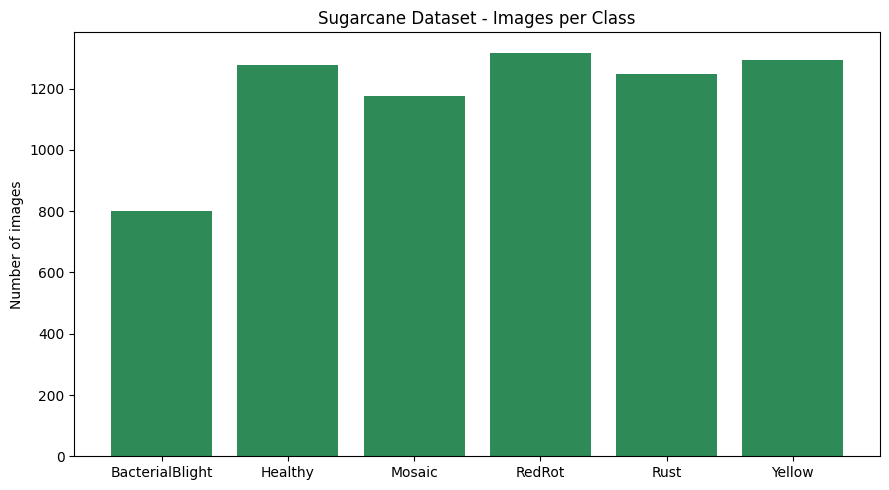

In [11]:
class_counts = {cls: count_images(os.path.join(FINAL_DIR, cls)) for cls in sorted(os.listdir(FINAL_DIR))}

for cls, n in class_counts.items():
    print(f"{cls}: {n}")
print(f"\nTotal: {sum(class_counts.values())} images in {len(class_counts)} classes")

plt.figure(figsize=(9, 5))
plt.bar(class_counts.keys(), class_counts.values(), color="seagreen")
plt.ylabel("Number of images")
plt.title("Sugarcane Dataset - Images per Class")
plt.tight_layout()
plt.show()

Bacterial Blight has fewer images than the other classes, so class weights are used during training (section 4).

## 3. Loading the Data

`image_dataset_from_directory` reads the images from the merged folder and splits them 80% for training and 20% for validation. The same seed is used for both calls so the two subsets do not overlap.

In [12]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    FINAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="training", seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    FINAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="validation", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 7111 files belonging to 6 classes.
Using 5689 files for training.
Found 7111 files belonging to 6 classes.
Using 1422 files for validation.
Classes: ['BacterialBlight', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Number of classes: 6


## 4. Class Weights

Because of the class imbalance, each class gets a weight that is higher for smaller classes. This makes mistakes on rare classes (like Bacterial Blight) cost more during training.

In [13]:
labels_flat = []
for i, cls in enumerate(class_names):
    labels_flat.extend([i] * count_images(os.path.join(FINAL_DIR, cls)))
labels_flat = np.array(labels_flat)

cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}

for i, cls in enumerate(class_names):
    print(f"{cls}: {class_weight_dict[i]:.3f}")

BacterialBlight: 1.481
Healthy: 0.929
Mosaic: 1.008
RedRot: 0.899
Rust: 0.950
Yellow: 0.916


## 5. Augmentation and Preprocessing

Random flips, rotation, zoom, brightness and contrast are applied to the training images only. This helps the model handle different camera angles and lighting. The validation images are only preprocessed, not augmented, so the validation score stays consistent.

In [14]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")


def prep_train(img, lbl):
    return preprocess_input(augmentation(img)), lbl


def prep_val(img, lbl):
    return preprocess_input(img), lbl


train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p = val_ds.map(prep_val, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

## 6. Model

EfficientNetB0 is used as the base model with ImageNet weights and without its original top layer. On top of it we add:

- Global average pooling to turn the feature maps into one vector
- Batch normalization
- Dropout (0.4) to reduce overfitting
- A dense softmax layer with one output per class

The base model starts frozen so that only the new head is trained in the first phase.

In [15]:
base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs, name="sugarcane_efficientnetb0")
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sugarcane_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,377 (15.50 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

### 6.1 Callbacks

- **EarlyStopping:** stops a phase when validation accuracy stops improving and goes back to the best weights.
- **ModelCheckpoint:** saves the model with the best validation accuracy to `sugarcane_best.keras`.
- **ReduceLROnPlateau:** lowers the learning rate when validation loss stops improving.

The same callbacks are used for all three phases.

In [16]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=3, restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    f"{OUTPUT_DIR}/sugarcane_best.keras", monitor="val_accuracy", save_best_only=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
)

callbacks = [early_stop, checkpoint, reduce_lr]

## 7. Training

Training is done in three phases. The learning rate gets smaller in every phase, so the pre-trained weights are changed gently once the base model is unfrozen.

| Phase | Base model | Learning rate | Max epochs |
|---|---|---|---|
| 1 | Frozen | 1e-3 | 5 |
| 2 | Fully unfrozen | 1e-4 | 10 |
| 3 | Fully unfrozen | 3e-5 | 15 |

### Phase 1: Frozen base

Only the new classification head is trained. This gives the head sensible weights before the base model is touched.

In [17]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=5,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 1 best validation accuracy: {max(h1.history['val_accuracy']) * 100:.2f}%")

Epoch 1/5


2026-10-27 10:02:36.699954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:02:36.885435: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:02:37.437391: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:02:37.588387: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:02:38.458277: E external/local_xla/xla/stream_

44/45 ━━━━━━━━━━━━━━━━━━━━ 0s 620ms/step - accuracy: 0.3439 - loss: 2.0025

2026-10-27 10:03:20.733246: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:20.886654: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:21.289752: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:21.432132: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:22.236683: E external/local_xla/xla/stream_

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 987ms/step - accuracy: 0.3468 - loss: 1.9916

2026-10-27 10:03:42.603689: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:42.742704: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:43.061701: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:43.203998: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:03:43.981583: E external/local_xla/xla/stream_

45/45 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.4753 - loss: 1.5124 - val_accuracy: 0.7152 - val_loss: 1.0239 - learning_rate: 0.0010
Epoch 2/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 826ms/step - accuracy: 0.6869 - loss: 0.8574 - val_accuracy: 0.7722 - val_loss: 0.8187 - learning_rate: 0.0010
Epoch 3/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 827ms/step - accuracy: 0.7340 - loss: 0.7223 - val_accuracy: 0.8045 - val_loss: 0.6780 - learning_rate: 0.0010
Epoch 4/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 828ms/step - accuracy: 0.7558 - loss: 0.6490 - val_accuracy: 0.8411 - val_loss: 0.5675 - learning_rate: 0.0010
Epoch 5/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 811ms/step - accuracy: 0.7905 - loss: 0.5685 - val_accuracy: 0.8368 - val_loss: 0.4960 - learning_rate: 0.0010
Phase 1 best validation accuracy: 84.11%


### Phase 2: Full fine-tuning (lr = 1e-4)

The whole base model is unfrozen so the pre-trained features can adapt to sugarcane leaves.

In [18]:
base_model.trainable = True

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 2 best validation accuracy: {max(h2.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-27 10:07:11.659824: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:07:11.890002: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:07:16.454906: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[128,96,113,113]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,96,115,115]{3,2,1,0}, f32[96,1,3,3]{3,2,1,0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, feature_group_count=96, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_al

44/45 ━━━━━━━━━━━━━━━━━━━━ 0s 686ms/step - accuracy: 0.5970 - loss: 1.1442

2026-10-27 10:08:34.419497: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:08:34.595836: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


45/45 ━━━━━━━━━━━━━━━━━━━━ 176s 2s/step - accuracy: 0.6778 - loss: 0.8817 - val_accuracy: 0.8354 - val_loss: 0.4430 - learning_rate: 1.0000e-04
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 882ms/step - accuracy: 0.8409 - loss: 0.4302 - val_accuracy: 0.8973 - val_loss: 0.2690 - learning_rate: 1.0000e-04
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 870ms/step - accuracy: 0.8933 - loss: 0.2897 - val_accuracy: 0.9255 - val_loss: 0.1914 - learning_rate: 1.0000e-04
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 872ms/step - accuracy: 0.9309 - loss: 0.1892 - val_accuracy: 0.9444 - val_loss: 0.1549 - learning_rate: 1.0000e-04
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 870ms/step - accuracy: 0.9436 - loss: 0.1555 - val_accuracy: 0.9508 - val_loss: 0.1418 - learning_rate: 1.0000e-04
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 882ms/step - accuracy: 0.9539 - loss: 0.1265 - val_accuracy: 0.9669 - val_loss: 0.1031 - learning_rate: 1.0000e-04
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 40s 841ms/step - accuracy: 0.9643

### Phase 3: Extended fine-tuning (lr = 3e-5)

Training continues with a smaller learning rate for finer updates.

In [19]:
model.compile(optimizer=keras.optimizers.Adam(3e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 3 best validation accuracy: {max(h3.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.9622 - loss: 0.1053 - val_accuracy: 0.9641 - val_loss: 0.1092 - learning_rate: 3.0000e-05
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 41s 853ms/step - accuracy: 0.9661 - loss: 0.0931 - val_accuracy: 0.9662 - val_loss: 0.1111 - learning_rate: 3.0000e-05
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 41s 846ms/step - accuracy: 0.9689 - loss: 0.0839 - val_accuracy: 0.9648 - val_loss: 0.1100 - learning_rate: 9.0000e-06
Phase 3 best validation accuracy: 96.62%


### 7.1 Training curves

The plots below join all three phases. The dashed vertical lines show where a new phase starts.

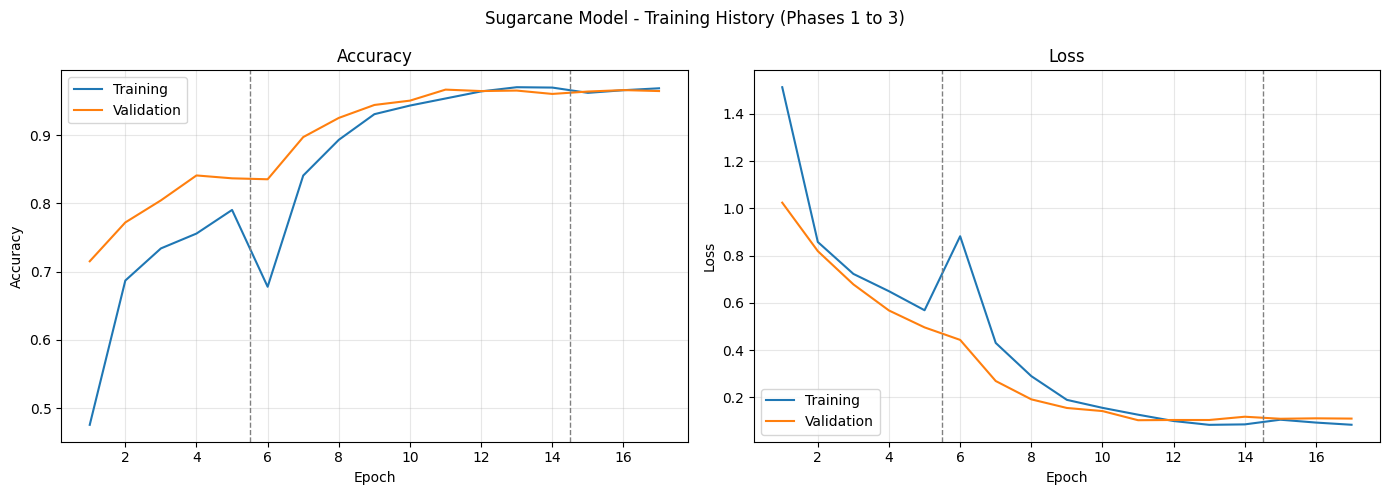

In [20]:
histories = [h1, h2, h3]

train_acc, val_acc, train_loss, val_loss = [], [], [], []
phase_ends = []
for h in histories:
    train_acc += h.history["accuracy"]
    val_acc += h.history["val_accuracy"]
    train_loss += h.history["loss"]
    val_loss += h.history["val_loss"]
    phase_ends.append(len(train_acc))

epochs_range = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_acc, label="Training")
axes[0].plot(epochs_range, val_acc, label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(epochs_range, train_loss, label="Training")
axes[1].plot(epochs_range, val_loss, label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

for ax in axes:
    for end in phase_ends[:-1]:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Sugarcane Model - Training History (Phases 1 to 3)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sugarcane_training_curves.png", dpi=150)
plt.show()

## 8. Evaluation

The model is evaluated on the validation set (20% of the images, never used for weight updates). Precision, recall and F1-score are reported for every class, followed by the confusion matrix.

In [21]:
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

val_accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {val_accuracy * 100:.2f}%  ({len(y_true)} images)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

2026-10-27 10:18:50.543936: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:18:50.687528: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:18:51.042469: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:18:51.185084: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 10:18:51.957488: E external/local_xla/xla/stream_

Validation accuracy: 96.41%  (1422 images)

                 precision    recall  f1-score   support

BacterialBlight     1.0000    1.0000    1.0000       139
        Healthy     0.8861    0.9842    0.9326       253
         Mosaic     0.9766    0.8601    0.9147       243
         RedRot     0.9888    0.9962    0.9925       266
           Rust     0.9706    0.9962    0.9832       265
         Yellow     0.9879    0.9570    0.9722       256

       accuracy                         0.9641      1422
      macro avg     0.9683    0.9656    0.9659      1422
   weighted avg     0.9660    0.9641    0.9639      1422



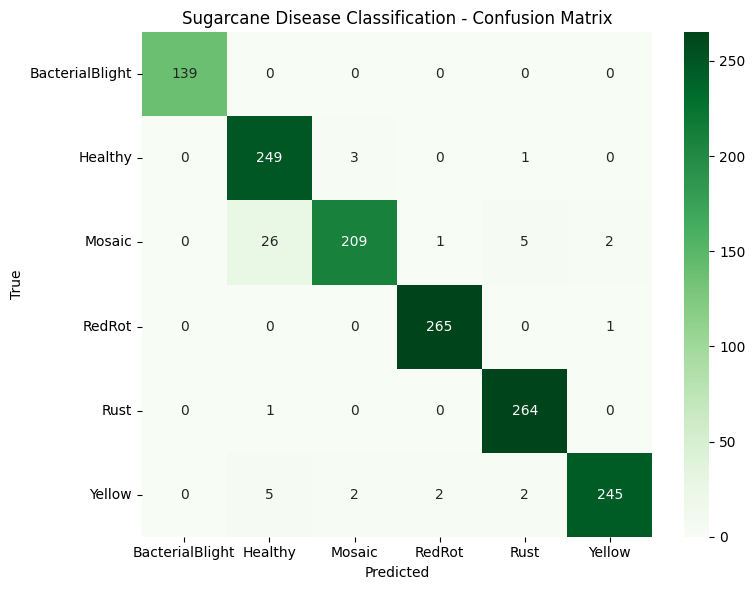

In [22]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Sugarcane Disease Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sugarcane_confusion_matrix.png", dpi=150)
plt.show()

### 8.1 Sample predictions

A batch of validation images with the true label, the predicted label and the model's confidence. Green titles are correct predictions and red titles are mistakes.

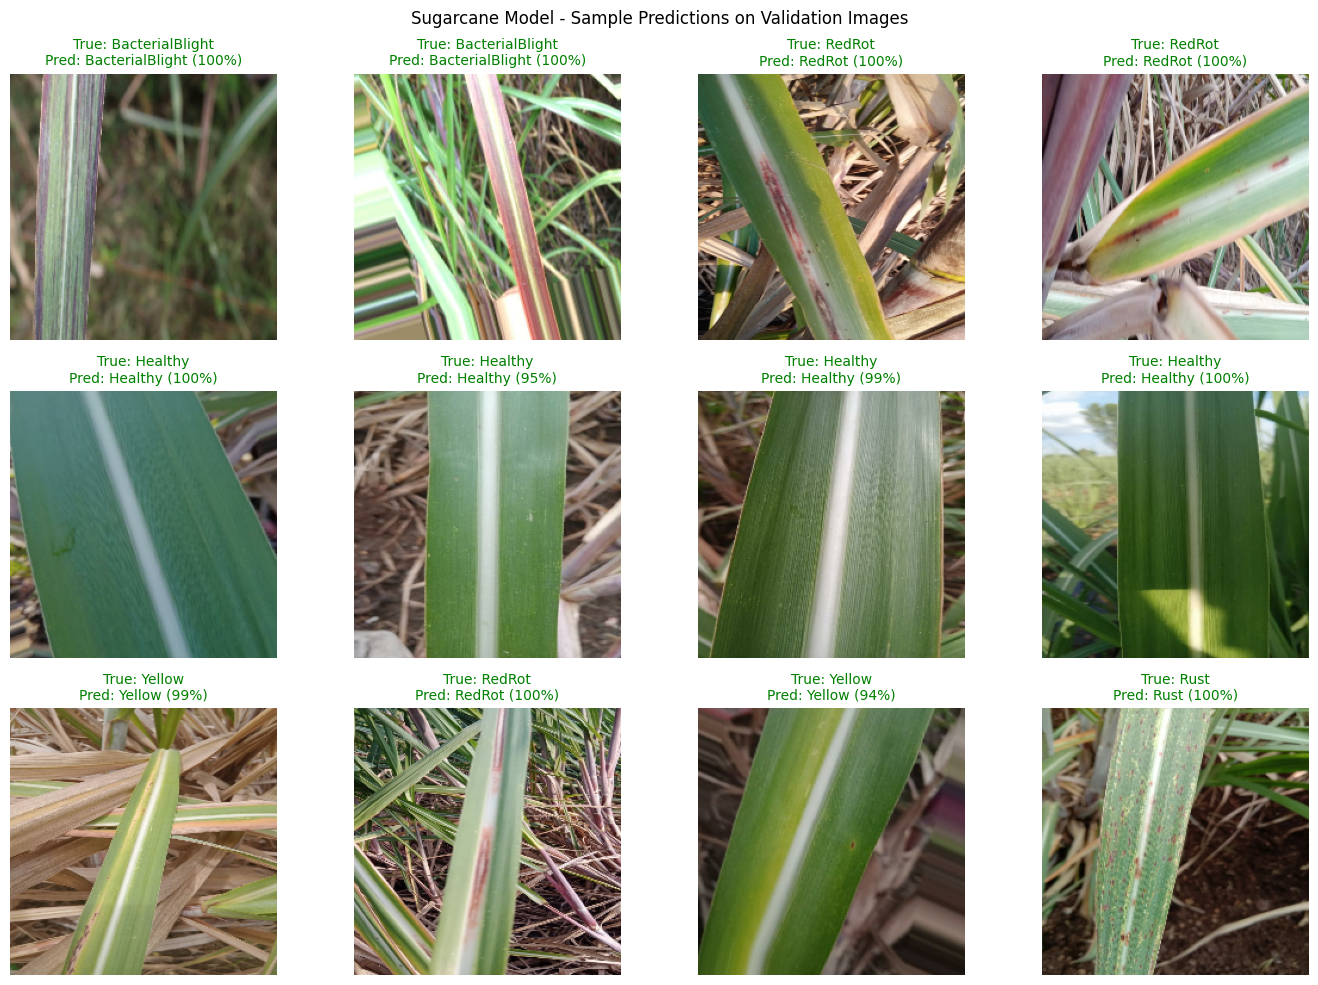

In [23]:
sample_images, sample_labels = next(iter(val_ds))
sample_probs = model.predict(preprocess_input(sample_images), verbose=0)

sample_true = np.argmax(sample_labels.numpy(), axis=1)
sample_pred = np.argmax(sample_probs, axis=1)

plt.figure(figsize=(14, 10))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.axis("off")

    confidence = sample_probs[i][sample_pred[i]] * 100
    correct = sample_true[i] == sample_pred[i]
    plt.title(f"True: {class_names[sample_true[i]]}\nPred: {class_names[sample_pred[i]]} ({confidence:.0f}%)",
              fontsize=10, color="green" if correct else "red")

plt.suptitle("Sugarcane Model - Sample Predictions on Validation Images")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sugarcane_sample_predictions.png", dpi=150)
plt.show()

## 9. Saving the Model

The final model is saved together with two JSON files that the CropGuard AI backend needs:

- `sugarcane_class_names.json`: the class labels in the same order as the model outputs, in the form `sugarcane__<disease>`
- `sugarcane_class_map.json`: maps each label to the crop name and a readable disease name

Everything is then packed into one zip file.

In [24]:
model.save(f"{OUTPUT_DIR}/sugarcane_final.keras")
size_mb = os.path.getsize(f"{OUTPUT_DIR}/sugarcane_final.keras") / 1024 / 1024
print(f"Model saved ({size_mb:.1f} MB)")

Model saved (47.1 MB)


In [25]:
DISEASE_DISPLAY_NAMES = {
    "BacterialBlight": "Bacterial Blight",
    "Healthy": "Healthy",
    "Mosaic": "Mosaic",
    "RedRot": "Red Rot",
    "Rust": "Rust",
    "Yellow": "Yellow Disease",
}

sugarcane_class_map = {}
production_class_names = []

for cls in class_names:
    key = "sugarcane__" + cls.lower()
    production_class_names.append(key)
    sugarcane_class_map[key] = {"crop": "Sugarcane", "disease": DISEASE_DISPLAY_NAMES.get(cls, cls)}

with open(f"{OUTPUT_DIR}/sugarcane_class_map.json", "w") as f:
    json.dump(sugarcane_class_map, f, indent=2)
with open(f"{OUTPUT_DIR}/sugarcane_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)

print(json.dumps(sugarcane_class_map, indent=2))

{
  "sugarcane__bacterialblight": {
    "crop": "Sugarcane",
    "disease": "Bacterial Blight"
  },
  "sugarcane__healthy": {
    "crop": "Sugarcane",
    "disease": "Healthy"
  },
  "sugarcane__mosaic": {
    "crop": "Sugarcane",
    "disease": "Mosaic"
  },
  "sugarcane__redrot": {
    "crop": "Sugarcane",
    "disease": "Red Rot"
  },
  "sugarcane__rust": {
    "crop": "Sugarcane",
    "disease": "Rust"
  },
  "sugarcane__yellow": {
    "crop": "Sugarcane",
    "disease": "Yellow Disease"
  }
}


In [26]:
files = [
    f"{OUTPUT_DIR}/sugarcane_final.keras",
    f"{OUTPUT_DIR}/sugarcane_best.keras",
    f"{OUTPUT_DIR}/sugarcane_class_map.json",
    f"{OUTPUT_DIR}/sugarcane_class_names.json",
    f"{OUTPUT_DIR}/sugarcane_confusion_matrix.png",
    f"{OUTPUT_DIR}/sugarcane_training_curves.png",
    f"{OUTPUT_DIR}/sugarcane_sample_predictions.png",
]

zip_path = f"{OUTPUT_DIR}/sugarcane_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
            print(f"added {os.path.basename(f)} ({os.path.getsize(f) / 1024 / 1024:.1f} MB)")
        else:
            print(f"missing: {f}")

print(f"\nPackage: {zip_path} ({os.path.getsize(zip_path) / 1024 / 1024:.1f} MB)")

added sugarcane_final.keras (47.1 MB)
added sugarcane_best.keras (47.1 MB)
added sugarcane_class_map.json (0.0 MB)
added sugarcane_class_names.json (0.0 MB)
added sugarcane_confusion_matrix.png (0.1 MB)
added sugarcane_training_curves.png (0.1 MB)
added sugarcane_sample_predictions.png (2.8 MB)

Package: /kaggle/working/sugarcane_model_package.zip (97.1 MB)


## 10. Summary and Limitations

**Summary**

- Sugarcane leaf images from a Roboflow dataset and a Kaggle dataset were merged and used to fine-tune an EfficientNetB0 model for 6 classes, using three training phases with decreasing learning rates.
- Class weights were used to handle the imbalance between classes, and augmentation was applied to the training images only.
- The final validation accuracy, per-class scores, confusion matrix and sample predictions are shown in section 8.
- The saved model and class files are used in the CropGuard AI website and mobile app.

**Limitations**

- The reported accuracy is validation accuracy. The same validation set was used for early stopping and for choosing the best checkpoint, and there is no separate test set, so the score can be slightly higher than what completely unseen images would give.
- The sources were merged and split again randomly. Every file of the Kaggle dataset was kept, so if that dataset contains exact copies of the same image (section 2.5 shows the numbers), a copy can end up in training and another one in validation. This makes the accuracy look better than it really is.
- Roboflow dataset versions can also contain augmented copies of the same photo. The duplicate check only finds files with exactly the same content, so it cannot find these.
- Bacterial Blight images come only from the Roboflow dataset, while the other classes have images from both sources. The model could partly use the style of the source to recognize this class.
- The images may be different from photos that farmers take with their phones in the field (lighting, background, camera quality), so accuracy in real use can be lower.

**Future work**

- Remove exact copies inside each source, and split the data by original photo.
- Test the model on a separate set of sugarcane images collected from fields in Pakistan.